In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from itertools import product
from collections import Counter
# --- Identidad visual INF672 "cuaderno científico" ---
INDIGO = "#4F46E5" # primario
PURPURA = "#7E22CE" # apoyo
CORAL = "#F43F5E" # errores / advertencias / énfasis
TINTA = "#111827" # texto
CELDA = "#F9FAFB" # fondo de celda
HAIRLINE = "#E5E7EB"
mpl.rcParams.update({
 "font.family": ["DejaVu Sans", "sans-serif"],
 "font.size": 11,
 "axes.facecolor": CELDA,
 "figure.facecolor": "white",
 "axes.grid": True,
 "grid.color": HAIRLINE,
})
# Semilla: hace el azar reproducible (mismo resultado en cada corrida).
rng = np.random.default_rng(672)
print("Entorno listo. Paleta INF672 cargada.")

Entorno listo. Paleta INF672 cargada.


In [2]:
# Todos los pares posibles (d1, d2) con cada dado de 1 a 6.
espacio_muestral = list(product(range(1, 7), repeat=2)) # 36 pares
print(f"Total de resultados equiprobables: {len(espacio_muestral)}\n")
# Los mostramos como una rejilla 6x6 para verlos todos de un vistazo.
for d1 in range(1, 7):
 fila = " ".join(f"({d1},{d2})" for d2 in range(1, 7))
 print(fila)

Total de resultados equiprobables: 36

(1,1) (1,2) (1,3) (1,4) (1,5) (1,6)
(2,1) (2,2) (2,3) (2,4) (2,5) (2,6)
(3,1) (3,2) (3,3) (3,4) (3,5) (3,6)
(4,1) (4,2) (4,3) (4,4) (4,5) (4,6)
(5,1) (5,2) (5,3) (5,4) (5,5) (5,6)
(6,1) (6,2) (6,3) (6,4) (6,5) (6,6)


In [3]:
conteo = Counter(d1 + d2 for d1, d2 in espacio_muestral)
print(f"{'Suma':>5} {'Pares favorables':>17} {'Probabilidad':>14}")
print("-" * 40)
for suma in range(2, 13):
 favorables = conteo[suma]
 prob = favorables / 36
 print(f"{suma:>5} {favorables:>17} {prob:>10.4f} ({favorables}/36)")
print(f"\nP(suma = 7) = {conteo[7]}/36 = {conteo[7]/36:.4f}")

 Suma  Pares favorables   Probabilidad
----------------------------------------
    2                 1     0.0278 (1/36)
    3                 2     0.0556 (2/36)
    4                 3     0.0833 (3/36)
    5                 4     0.1111 (4/36)
    6                 5     0.1389 (5/36)
    7                 6     0.1667 (6/36)
    8                 5     0.1389 (5/36)
    9                 4     0.1111 (4/36)
   10                 3     0.0833 (3/36)
   11                 2     0.0556 (2/36)
   12                 1     0.0278 (1/36)

P(suma = 7) = 6/36 = 0.1667


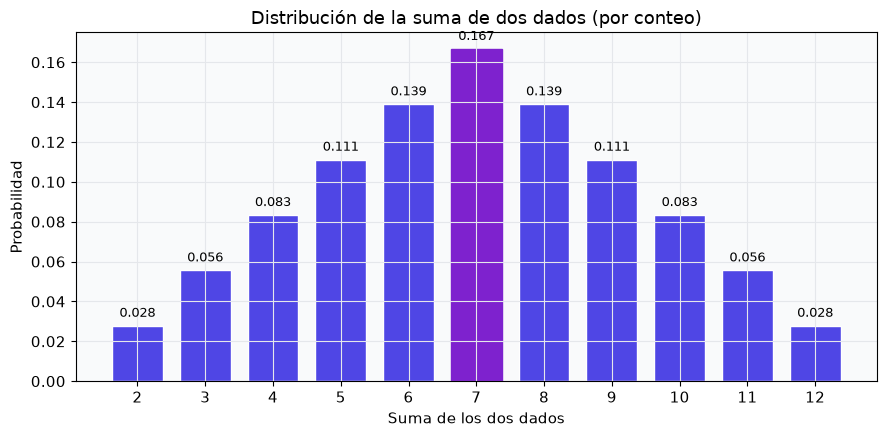

In [4]:
sumas = list(range(2, 13))
probs = [conteo[s] / 36 for s in sumas]
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(sumas, probs, color=INDIGO, edgecolor="white", width=0.75)
barras[sumas.index(7)].set_color(PURPURA) # resalta el máximo
for s, p in zip(sumas, probs):
 ax.text(s, p + 0.003, f"{p:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la suma de dos dados (por conteo)")
ax.set_xlabel("Suma de los dos dados"); ax.set_ylabel("Probabilidad")
ax.set_xticks(sumas)
plt.tight_layout(); plt.show()

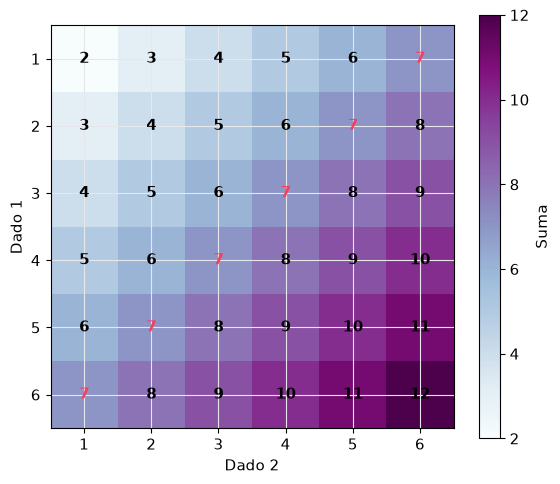

In [5]:
# Matriz 6x6 donde cada celda es la suma d1 + d2.
matriz = np.array([[d1 + d2 for d2 in range(1, 7)] for d1 in range(1, 7)])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(matriz, cmap="BuPu", origin="upper")
for i in range(6):
    for j in range(6):
        es_siete = (matriz[i, j] == 7)
        ax.text(j, i, matriz[i, j], ha="center", va="center",
            color=CORAL if es_siete else "black", fontweight="bold")
ax.set_xticks(range(6))
ax.set_xticklabels(range(1, 7))
ax.set_yticks(range(6))
ax.set_yticklabels(range(1, 7))

ax.set_xlabel("Dado 2"); ax.set_ylabel("Dado 1")
plt.colorbar(im, ax=ax, label="Suma"); plt.show()

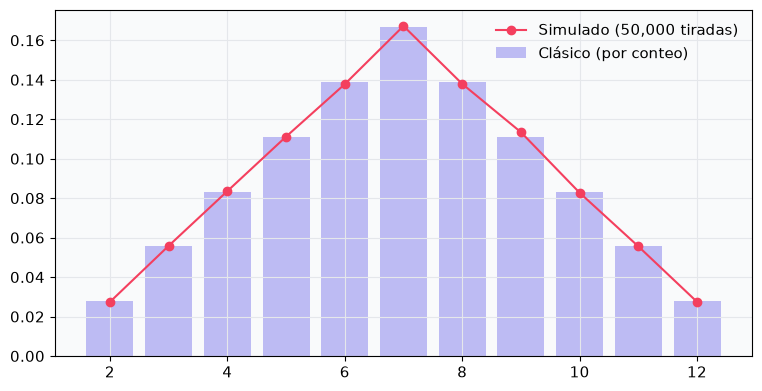

In [6]:
N = 50_000 # número de tiradas simuladas
d1 = rng.integers(1, 7, size=N) # N dados: enteros de 1 a 6
d2 = rng.integers(1, 7, size=N)
sumas_simuladas = d1 + d2 # suma elemento a elemento
conteo_sim = Counter(sumas_simuladas)
frec_obs = [conteo_sim[s] / N for s in sumas]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(sumas, probs, color=INDIGO, alpha=0.35, label="Clásico (por conteo)")
ax.plot(sumas, frec_obs, "o-", color=CORAL, label=f"Simulado ({N:,} tiradas)")
ax.legend(frameon=False); plt.show()

In [7]:
def frecuencia_acumulada(resultados):
  """Dada una secuencia de 0s y 1s (1 = ocurrió el evento),

  devuelve la fracción acumulada de 1s tras cada tirada[cite: 1].
  Ej.: [1, 0, 1, 1] -> [1.0, 0.5, 0.667, 0.75][cite: 1]
  """
  resultados = np.asarray(resultados)  #[cite: 1]
  aciertos_acumulados = np.cumsum(resultados)  #[cite: 1]
  tiradas = np.arange(1, len(resultados) + 1)  #[cite: 1]
  return aciertos_acumulados / tiradas  #[cite: 1]


print(frecuencia_acumulada([1, 0, 1, 1]))  #[cite: 1]

[1.         0.5        0.66666667 0.75      ]


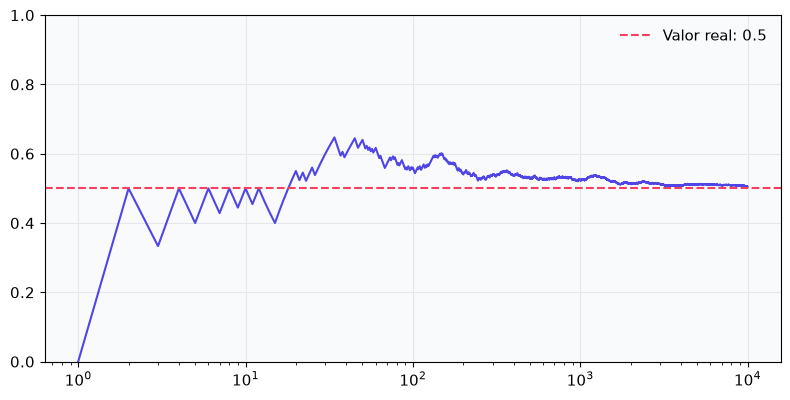

Estimación final: 0.5049 (el valor real es 0.5).


In [8]:
N = 10_000
lanzamientos = rng.integers(0, 2, size=N) # 1 = cara, 0 = cruz
frec = frecuencia_acumulada(lanzamientos)
fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(np.arange(1, N + 1), frec, color=INDIGO)
ax.axhline(0.5, color=CORAL, linestyle="--", label="Valor real: 0.5")
ax.set_xscale("log") # escala log en X: ver el caos inicial y la calma final
ax.set_ylim(0, 1); ax.legend(frameon=False); plt.show()
print(f"Estimación final: {frec[-1]:.4f} (el valor real es 0.5).")

In [9]:
# --- La naturaleza (secreto): NO mirar este número al razonar ---
P_VERDADERA = 0.62 # probabilidad real de "punta arriba"
N = 10_000
chinchetas = (rng.random(N) < P_VERDADERA).astype(int) # 0s y 1s
frec = frecuencia_acumulada(chinchetas)
estimacion = frec[-1]
print(f"Tras {N:,} lanzamientos, estimamos P(punta arriba) ~ {estimacion:.4f}")

Tras 10,000 lanzamientos, estimamos P(punta arriba) ~ 0.6192


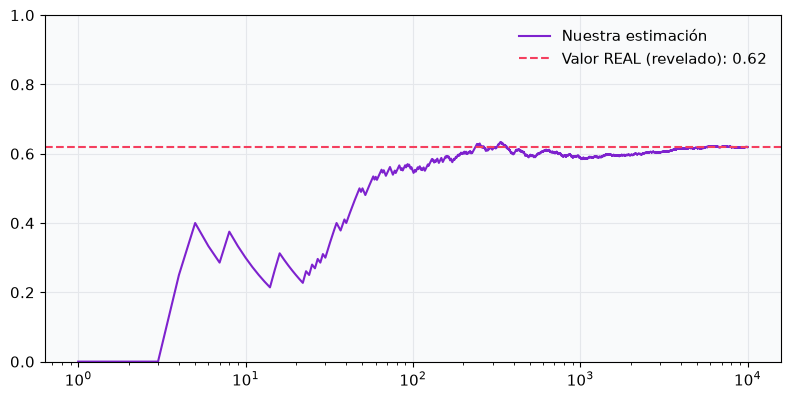

Estimación: 0.6192 | Real: 0.62 | Error: 0.0008


In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(np.arange(1, N + 1), frec, color=PURPURA, label="Nuestra estimación")
ax.axhline(P_VERDADERA, color=CORAL, linestyle="--",
 label=f"Valor REAL (revelado): {P_VERDADERA}")
ax.set_xscale("log"); ax.set_ylim(0, 1); ax.legend(frameon=False); plt.show()
print(f"Estimación: {estimacion:.4f} | Real: {P_VERDADERA} | Error: {abs(estimacion - P_VERDADERA):.4f}")

In [11]:
tamaños = [10, 100, 1_000, 10_000, 100_000]
estimaciones = []
for n in tamaños:
 muestra = (rng.random(n) < P_VERDADERA).astype(int)
 est = muestra.mean() # media = frecuencia de 1s
 estimaciones.append(est)
 print(f"{n:>8,} estimación={est:.4f} error={abs(est - P_VERDADERA):.4f}")

      10 estimación=0.4000 error=0.2200
     100 estimación=0.5600 error=0.0600
   1,000 estimación=0.6090 error=0.0110
  10,000 estimación=0.6156 error=0.0044
 100,000 estimación=0.6206 error=0.0006


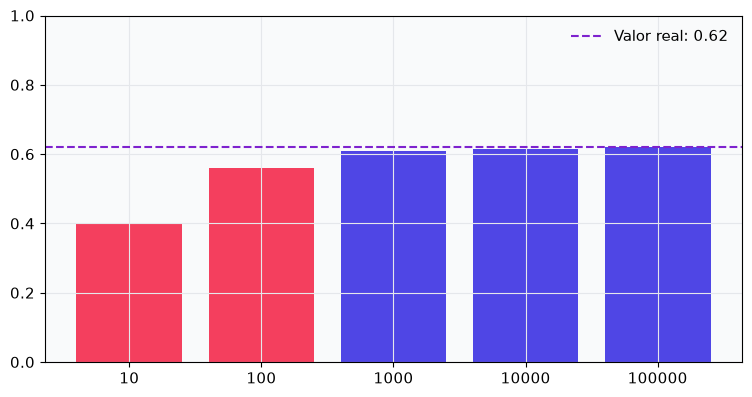

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
# coral si el error es grande (>0.03), índigo si es aceptable
colores = [CORAL if abs(e - P_VERDADERA) > 0.03 else INDIGO for e in estimaciones]
ax.bar([str(n) for n in tamaños], estimaciones, color=colores)
ax.axhline(P_VERDADERA, color=PURPURA, linestyle="--", label=f"Valor real: {P_VERDADERA}")
ax.set_ylim(0, 1); ax.legend(frameon=False); plt.show()

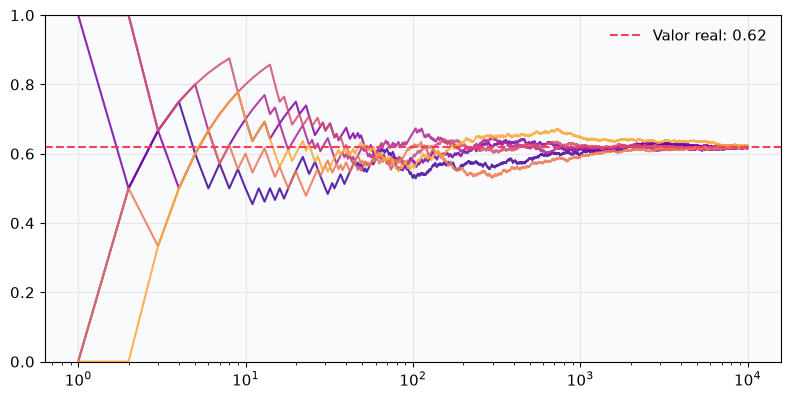

In [13]:
N = 10_000
n_corridas = 6
fig, ax = plt.subplots(figsize=(9.5, 4.5))
paleta = plt.cm.plasma(np.linspace(0.1, 0.8, n_corridas))
for k in range(n_corridas):
 rng_k = np.random.default_rng(k) # cada corrida, su propia semilla
 muestra = (rng_k.random(N) < P_VERDADERA).astype(int)
 ax.plot(np.arange(1, N + 1), frecuencia_acumulada(muestra),
 color=paleta[k], alpha=0.85)
ax.axhline(P_VERDADERA, color=CORAL, linestyle="--", label=f"Valor real: {P_VERDADERA}")
ax.set_xscale("log"); ax.set_ylim(0, 1); ax.legend(frameon=False); plt.show()